In [2]:
%pip install seaborn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
data = 'titanic.csv'
df = pd.read_csv(data)

In [4]:
df.shape
df.head()
df.tail()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 66.2 KB


In [6]:
num_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = df.select_dtypes(include=['str']).columns.tolist()
print("Numerical columns:", num_cols)
print("Categorical columns:", cat_cols)
print(df[num_cols].describe())


Numerical columns: ['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
Categorical columns: ['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked']
       PassengerId    Survived      Pclass         Age       SibSp  \
count   891.000000  891.000000  891.000000  714.000000  891.000000   
mean    446.000000    0.383838    2.308642   29.699118    0.523008   
std     257.353842    0.486592    0.836071   14.526497    1.102743   
min       1.000000    0.000000    1.000000    0.420000    0.000000   
25%     223.500000    0.000000    2.000000   20.125000    0.000000   
50%     446.000000    0.000000    3.000000   28.000000    0.000000   
75%     668.500000    1.000000    3.000000   38.000000    1.000000   
max     891.000000    1.000000    3.000000   80.000000    8.000000   

            Parch        Fare  
count  891.000000  891.000000  
mean     0.381594   32.204208  
std      0.806057   49.693429  
min      0.000000    0.000000  
25%      0.000000    7.910400  
50%      0.000000  

In [7]:
df_clean = df.copy() 

median_age = df_clean['Age'].median()
df_clean['Age'] = df_clean['Age'].fillna(median_age)

mode_embarked = df_clean['Embarked'].mode()[0]
df_clean['Embarked'] = df_clean['Embarked'].fillna(mode_embarked)

df_clean = df_clean.drop(columns=['Cabin'])

print("Remaining missing values:")
print(df_clean.isnull().sum())

Remaining missing values:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


In [8]:
# Check duplicates
dup_count = df_clean.duplicated().sum()
print(f"Duplicate rows: {dup_count}")

print("\nSex values:", df_clean['Sex'].unique())
print("Embarked values:", df_clean['Embarked'].unique())
print("Pclass values:", sorted(df_clean['Pclass'].unique()))

# No duplicates expected in Titanic; no spelling inconsistencies in core columns.
# If found, you would strip whitespace and standardise case here.

Duplicate rows: 0

Sex values: <StringArray>
['male', 'female']
Length: 2, dtype: str
Embarked values: <StringArray>
['S', 'C', 'Q']
Length: 3, dtype: str
Pclass values: [np.int64(1), np.int64(2), np.int64(3)]


Survival counts:
Survived
0    549
1    342
Name: count, dtype: int64

Survival rate by Sex:
Sex
female    0.742
male      0.189
Name: Survived, dtype: float64


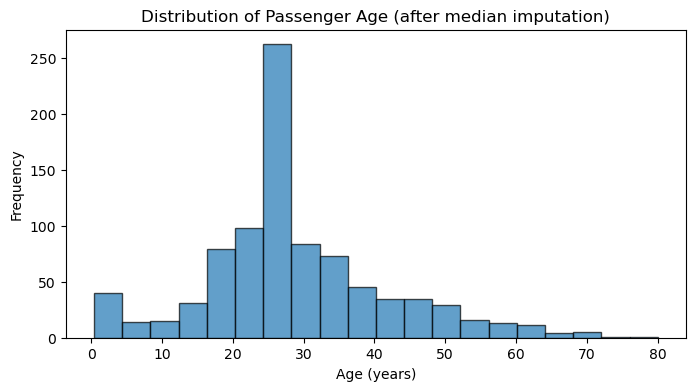

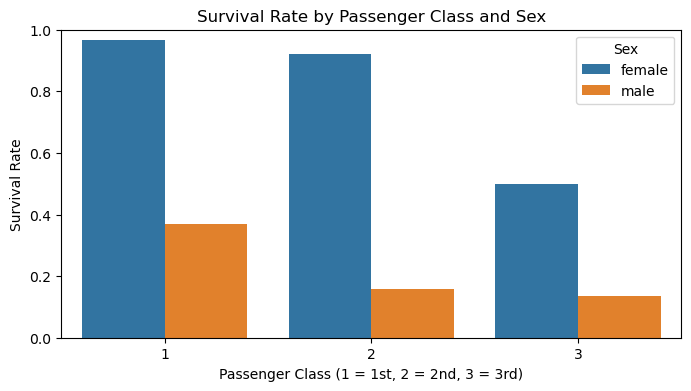

In [9]:
# Frequency counts for a categorical column
print("Survival counts:")
print(df_clean['Survived'].value_counts())
print("\nSurvival rate by Sex:")
print(df_clean.groupby('Sex')['Survived'].mean().round(3))

# Age distribution histogram
plt.figure(figsize=(8, 4))
plt.hist(df_clean['Age'], bins=20, edgecolor='black', alpha=0.7)
plt.title('Distribution of Passenger Age (after median imputation)')
plt.xlabel('Age (years)')
plt.ylabel('Frequency')
plt.show()

# Survival rate by Sex and Pclass
plt.figure(figsize=(8, 4))
sns.barplot(data=df_clean, x='Pclass', y='Survived', hue='Sex', errorbar=None)
plt.title('Survival Rate by Passenger Class and Sex')
plt.xlabel('Passenger Class (1 = 1st, 2 = 2nd, 3 = 3rd)')
plt.ylabel('Survival Rate')
plt.ylim(0, 1)
plt.show()

In [10]:
# One-hot encode nominal categories (no natural order)
# Sex and Embarked are nominal. Pclass is ordinal (1>2>3) but often treated as categorical for tree models.
df_encoded = pd.get_dummies(df_clean, columns=['Sex', 'Embarked'], drop_first=True, dtype=int)

print("Before encoding: columns =", df_clean.shape[1])
print("After encoding: columns =", df_encoded.shape[1])
print("\nNew column names:")
print([c for c in df_encoded.columns if 'Sex' in c or 'Embarked' in c])

Before encoding: columns = 11
After encoding: columns = 12

New column names:
['Sex_male', 'Embarked_Q', 'Embarked_S']


In [11]:
from sklearn.preprocessing import StandardScaler

# Features to scale (exclude PassengerId and target Survived)
scale_cols = ['Age', 'Fare', 'SibSp', 'Parch']
scaler = StandardScaler()
df_encoded[scale_cols] = scaler.fit_transform(df_encoded[scale_cols])

print("After scaling (mean≈0, std≈1):")
print(df_encoded[scale_cols].describe().loc[['mean', 'std']].round(2))


After scaling (mean≈0, std≈1):
      Age  Fare  SibSp  Parch
mean  0.0   0.0    0.0    0.0
std   1.0   1.0    1.0    1.0


In [12]:
# Final verification
print("Final shape:", df_encoded.shape)
print("Missing values remaining:", df_encoded.isnull().sum().sum())
print("Duplicate rows remaining:", df_encoded.duplicated().sum())

# Save to CSV
df_encoded.to_csv('titanic_prepared.csv', index=False)



Final shape: (891, 12)
Missing values remaining: 0
Duplicate rows remaining: 0

Saved as 'titanic_prepared.csv'

Prepared data sample:
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name       Age     SibSp  \
0                            Braund, Mr. Owen Harris -0.565736  0.432793   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  0.663861  0.432793   
2                             Heikkinen, Miss. Laina -0.258337 -0.474545   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  0.433312  0.432793   
4                           Allen, Mr. William Henry  0.433312 -0.474545   

      Parch            Ticket      Fare  Sex_male  Embarked_Q  Embarked_S  
0 -0.473674         A/5 21171 -0.502445         1           0           1  
1 -0.473674          PC 17599  0.786845